<a href="https://colab.research.google.com/github/AndreaFreemanfse/Flatiron/blob/main/Prompt_Engineering_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prompt 1

In this first method I try to reverse engineering a prompt with ChatGPT based on the requirments of the project.

I first submitted the following:

    Scenario: You're working at a retail chain, analyzing inventory turnover. The store manager needs to understand stock movement patterns to optimize ordering.

    Data Structure: DataFrame

    product_id
    category
    stock_level
    last_restock_date
    sales_last_30_days
    supplier_lead_time
    unit_cost
    Task: Generate code to:

    Calculate inventory turnover rates.
    Identify slow-moving items.
    Predict potential stockouts.
    Create visualizations.

# Response 1

1. Import libraries and prepare the data
import pandas as pdimport numpy as npimport matplotlib.pyplot as pltimport seaborn as sns# Convert dates to datetime formatdf["last_restock_date"] = pd.to_datetime(df["last_restock_date"])# Check data types and missing valuesprint(df.info())print(df.isnull().sum())



2. Calculate inventory turnover rates
Inventory turnover measures how quickly products sell relative to the inventory held. Since we have sales for the last 30 days, we'll estimate turnover using the average inventory value as a proxy.
# Estimate average daily sales over the last 30 daysdf["daily_sales"] = df["sales_last_30_days"] / 30# Estimate 30-day inventory turnoverdf["inventory_turnover_30d"] = np.where(    df["stock_level"] > 0,    df["sales_last_30_days"] / df["stock_level"],    np.nan)# Estimate days of inventory remainingdf["days_of_inventory"] = np.where(    df["daily_sales"] > 0,    df["stock_level"] / df["daily_sales"],    np.inf)print(df[[    "product_id",    "category",    "inventory_turnover_30d",    "days_of_inventory"]].head())



Interpretation:
- Higher turnover generally means inventory is moving quickly.
- Lower turnover may indicate excess inventory or weak demand.
- Fewer days of inventory means a product may need replenishment soon.
Note: This is a simplified turnover proxy, not the formal accounting inventory turnover ratio, which uses cost of goods sold divided by average inventory value. That calculation would require historical inventory or cost-of-goods-sold data.
3. Identify slow-moving items
We'll flag products that have sold no more than 20% of their current stock over the last 30 days, including products with no recorded sales.
# Flag products with low sales relative to current stockdf["slow_moving"] = (    (df["stock_level"] > 0) &    (df["inventory_turnover_30d"] <= 0.20))slow_moving_items = df[df["slow_moving"]].sort_values(    "inventory_turnover_30d")print("Slow-moving inventory:")print(slow_moving_items[[    "product_id",    "category",    "stock_level",    "sales_last_30_days",    "inventory_turnover_30d"]])



The 0.20 threshold is an example business rule. You can adjust it based on your store's sales patterns and the product category.
4. Predict potential stockouts
Estimate how many days of inventory remain at the current sales rate, then compare that estimate against supplier lead time.
# Estimate whether inventory will last until the next deliverydf["potential_stockout"] = (    (df["daily_sales"] > 0) &    (df["days_of_inventory"] <= df["supplier_lead_time"]))# Estimate reorder quantity needed to cover lead timedf["reorder_quantity"] = np.maximum(    0,    np.ceil(        df["daily_sales"] * df["supplier_lead_time"]        - df["stock_level"]    ))# Classify stockout riskdf["stockout_risk"] = np.select(    [        df["stock_level"] <= 0,        df["potential_stockout"],        df["days_of_inventory"] <= df["supplier_lead_time"] + 7    ],    [        "Out of stock",        "High risk",        "Medium risk"    ],    default="Low risk")stockout_predictions = df.sort_values(    "days_of_inventory")print("Potential stockouts:")print(stockout_predictions[[



This prediction assumes sales continue at their recent average rate and that supplier lead time is measured in days. It does not account for demand spikes, incoming purchase orders, or safety stock.
5. Create visualizations
A. Inventory turnover by category
category_turnover = (    df.groupby("category")["inventory_turnover_30d"]    .mean()    .sort_values(ascending=False)    .reset_index())plt.figure(figsize=(10, 6))sns.barplot(    data=category_turnover,    x="category",    y="inventory_turnover_30d")plt.title("Average 30-Day Inventory Turnover by Category")plt.xlabel("Product Category")plt.ylabel("Sales / Current Stock")plt.xticks(rotation=45, ha="right")plt.tight_layout()plt.show()



B. Identify slow-moving inventory
plt.figure(figsize=(10, 6))sns.scatterplot(    data=df,    x="sales_last_30_days",    y="stock_level",    hue="slow_moving",    size="unit_cost",    sizes=(30, 250))plt.title("Stock Levels vs. Sales in the Last 30 Days")plt.xlabel("Units Sold in Last 30 Days")plt.ylabel("Current Stock Level")plt.tight_layout()plt.show()



Products with high stock levels and low sales are potential candidates for promotions, reduced future orders, or inventory transfers.
C. Stockout risk by category
risk_counts = (    df.groupby(["category", "stockout_risk"])    .size()    .reset_index(name="product_count"))risk_pivot = risk_counts.pivot(    index="category",    columns="stockout_risk",    values="product_count").fillna(0)risk_pivot.plot(    kind="bar",    stacked=True,    figsize=(11, 6))plt.title("Stockout Risk by Product Category")plt.xlabel("Category")plt.ylabel("Number of Products")plt.xticks(rotation=45, ha="right")plt.legend(title="Stockout Risk")plt.tight_layout()plt.show()



D. Days of inventory remaining
plot_df = df.replace([np.inf, -np.inf], np.nan).dropna(    subset=["days_of_inventory"])plt.figure(figsize=(10, 6))sns.histplot(    data=plot_df,    x="days_of_inventory",    bins=20)plt.title("Distribution of Days of Inventory Remaining")plt.xlabel("Estimated Days Remaining")plt.ylabel("Number of Products")plt.tight_layout()plt.show()



6. Generate a final inventory report
Use this summary to give the store manager a quick overview of inventory conditions.
print("INVENTORY ANALYSIS SUMMARY")print("-" * 35)print(f"Total products: {len(df)}")print(f"Slow-moving products: {df['slow_moving'].sum()}")print(f"Products at high stockout risk: "      f"{(df['stockout_risk'] == 'High risk').sum()}")print(f"Products currently out of stock: "      f"{(df['stockout_risk'] == 'Out of stock').sum()}")print("\nProducts to prioritize for replenishment:")print(    df[df["stockout_risk"].isin(["Out of stock", "High risk"])]    .sort_values("days_of_inventory")[        [            "product_id",            "category",            "stock_level",            "days_of_inventory",            "supplier_lead_time",            "reorder_quantity"        ]    ].head(10))



Expected business outcomes
Analysis	Business purpose
Inventory turnover	Identify products and categories that sell quickly or slowly.
Slow-moving items	Find excess stock that may require promotions or reduced ordering.
Stockout prediction	Prioritize replenishment before inventory runs out.
Visualizations	Communicate inventory trends to the store manager.
Inventory report	Support ordering and purchasing decisions.

Important distinction: These calculations are estimates based on the available columns. A more reliable replenishment model would also include incoming purchase orders, historical daily sales, seasonal demand, and safety-stock targets.

# Prompt Refinement 1

Generate a prompt based on this response


**Prompt: Retail Inventory Turnover Analysis**

You are a data analyst working for a retail chain. Using Python, Pandas, NumPy, Matplotlib, and Seaborn, analyze inventory data stored in a DataFrame with the following columns:

- `product_id`
- `category`
- `stock_level`
- `last_restock_date`
- `sales_last_30_days`
- `supplier_lead_time`
- `unit_cost`

Complete the following tasks:

1. **Calculate inventory turnover:** Estimate 30-day inventory turnover using recent sales and current stock levels. Explain the limitations of this estimate compared with the traditional cost-of-goods-sold formula.

2. **Identify slow-moving products:** Flag products with low sales relative to available inventory. Summarize slow-moving items by product and category.

3. **Predict potential stockouts:** Estimate average daily sales and days of inventory remaining. Compare projected inventory depletion against supplier lead times, flag stockout risks, and calculate suggested reorder quantities.

4. **Create visualizations:** Generate clear, labeled charts showing:
   - Average inventory turnover by category.
   - Stock levels versus recent sales.
   - Stockout risk by category.
   - Distribution of estimated days of inventory remaining.

5. **Generate a business summary:** Report the total number of products, slow-moving items, high-risk stockouts, and products already out of stock. Identify the products that should be prioritized for replenishment.

Use clean, well-commented Python code and handle missing values, zero stock, and zero sales appropriately. Explain the assumptions behind each calculation, avoid misleading predictions, and provide actionable recommendations to help the store manager optimize inventory levels, reduce excess stock, and prevent stockouts. Return a single python pastable response

I added additional details of returning the code in a single pastable response to avoid the formating issues of the first response

# Results

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. PREPARE THE DATA
# ============================================================

# Assumes your inventory data is already loaded into df
df = df.copy()

df["last_restock_date"] = pd.to_datetime(
    df["last_restock_date"], errors="coerce"
)

numeric_cols = [
    "stock_level",
    "sales_last_30_days",
    "supplier_lead_time",
    "unit_cost"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing or invalid essential inventory values
df = df.dropna(
    subset=[
        "product_id",
        "category",
        "stock_level",
        "sales_last_30_days",
        "supplier_lead_time",
        "unit_cost"
    ]
).copy()

# Prevent negative values from distorting inventory calculations
df = df[
    (df["stock_level"] >= 0) &
    (df["sales_last_30_days"] >= 0) &
    (df["supplier_lead_time"] >= 0) &
    (df["unit_cost"] >= 0)
].copy()

print("DATA PREPARATION")
print("=" * 50)
print(f"Products analyzed: {len(df)}")
print(f"Missing values:\n{df.isnull().sum()}")


# ============================================================
# 2. CALCULATE INVENTORY TURNOVER
# ============================================================

# Average daily sales based on the last 30 days
df["daily_sales"] = df["sales_last_30_days"] / 30

# Estimated 30-day turnover proxy
# This is sales divided by current stock, not the formal
# accounting inventory turnover ratio.
df["inventory_turnover_30d"] = np.where(
    df["stock_level"] > 0,
    df["sales_last_30_days"] / df["stock_level"],
    np.nan
)

# Estimate days of inventory remaining
df["days_of_inventory"] = np.where(
    df["daily_sales"] > 0,
    df["stock_level"] / df["daily_sales"],
    np.inf
)

print("\nINVENTORY TURNOVER")
print("=" * 50)

print(
    df[[
        "product_id",
        "category",
        "stock_level",
        "sales_last_30_days",
        "inventory_turnover_30d",
        "days_of_inventory"
    ]].head(10)
)

# Traditional accounting turnover uses cost of goods sold
# divided by average inventory value. Those historical
# values are not available in this dataset.


# ============================================================
# 3. IDENTIFY SLOW-MOVING PRODUCTS
# ============================================================

# Flag products that sold 20% or less of current stock
df["slow_moving"] = (
    (df["stock_level"] > 0) &
    (
        df["sales_last_30_days"]
        <= 0.20 * df["stock_level"]
    )
)

slow_moving_items = df[
    df["slow_moving"]
].sort_values("inventory_turnover_30d")

print("\nSLOW-MOVING PRODUCTS")
print("=" * 50)

print(
    slow_moving_items[[
        "product_id",
        "category",
        "stock_level",
        "sales_last_30_days",
        "inventory_turnover_30d"
    ]]
)

print("\nSlow-moving products by category:")

print(
    slow_moving_items.groupby("category")["product_id"]
    .count()
    .sort_values(ascending=False)
)


# ============================================================
# 4. PREDICT POTENTIAL STOCKOUTS
# ============================================================

# A product is high risk when estimated inventory coverage
# is no greater than supplier lead time.
df["potential_stockout"] = (
    (df["daily_sales"] > 0) &
    (
        df["days_of_inventory"]
        <= df["supplier_lead_time"]
    )
)

# Baseline reorder quantity to cover demand during lead time.
# Safety stock and incoming shipments are not included.
df["reorder_quantity"] = np.maximum(
    0,
    np.ceil(
        df["daily_sales"] * df["supplier_lead_time"]
        - df["stock_level"]
    )
)

# Assign inventory risk categories
df["stockout_risk"] = np.select(
    [
        df["stock_level"] <= 0,
        df["potential_stockout"],
        (
            df["days_of_inventory"]
            <= df["supplier_lead_time"] + 7
        )
    ],
    [
        "Out of stock",
        "High risk",
        "Medium risk"
    ],
    default="Low risk"
)

print("\nSTOCKOUT PREDICTIONS")
print("=" * 50)

print(
    df.sort_values("days_of_inventory")[[
        "product_id",
        "category",
        "stock_level",
        "daily_sales",
        "days_of_inventory",
        "supplier_lead_time",
        "stockout_risk",
        "reorder_quantity"
    ]].head(20)
)


# ============================================================
# 5. VISUALIZATION 1: INVENTORY TURNOVER BY CATEGORY
# ============================================================

category_turnover = (
    df.groupby("category")["inventory_turnover_30d"]
    .mean()
    .reset_index()
    .sort_values("inventory_turnover_30d", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_turnover,
    x="category",
    y="inventory_turnover_30d"
)

plt.title("Average 30-Day Inventory Turnover by Category")
plt.xlabel("Product Category")
plt.ylabel("Estimated Turnover (Sales / Current Stock)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# 6. VISUALIZATION 2: STOCK LEVELS VS. SALES
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sales_last_30_days",
    y="stock_level",
    hue="slow_moving",
    size="unit_cost",
    sizes=(30, 250)
)

plt.title("Current Stock Levels vs. Sales in Last 30 Days")
plt.xlabel("Units Sold in Last 30 Days")
plt.ylabel("Current Stock Level")
plt.tight_layout()
plt.show()


# ============================================================
# 7. VISUALIZATION 3: STOCKOUT RISK BY CATEGORY
# ============================================================

risk_counts = (
    df.groupby(["category", "stockout_risk"])
    .size()
    .reset_index(name="product_count")
)

risk_pivot = risk_counts.pivot(
    index="category",
    columns="stockout_risk",
    values="product_count"
).fillna(0)

risk_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Stockout Risk by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Stockout Risk")
plt.tight_layout()
plt.show()


# ============================================================
# 8. VISUALIZATION 4: DAYS OF INVENTORY REMAINING
# ============================================================

# Infinite values occur when sales are zero.
# Exclude them from the histogram.
plot_df = df.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=["days_of_inventory"])

plt.figure(figsize=(10, 6))

sns.histplot(
    data=plot_df,
    x="days_of_inventory",
    bins=20
)

plt.title("Distribution of Estimated Days of Inventory Remaining")
plt.xlabel("Estimated Days Remaining")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


# ============================================================
# 9. BUSINESS SUMMARY
# ============================================================

print("\nRETAIL INVENTORY ANALYSIS SUMMARY")
print("=" * 50)

print(f"Total products analyzed: {len(df)}")
print(f"Slow-moving products: {df['slow_moving'].sum()}")
print(
    "High-risk products: "
    f"{(df['stockout_risk'] == 'High risk').sum()}"
)
print(
    "Products out of stock: "
    f"{(df['stockout_risk'] == 'Out of stock').sum()}"
)
print(
    "Medium-risk products: "
    f"{(df['stockout_risk'] == 'Medium risk').sum()}"
)

print("\nTOP PRODUCTS TO PRIORITIZE FOR REPLENISHMENT")
print("=" * 50)

priority_items = df[
    df["stockout_risk"].isin([
        "Out of stock",
        "High risk"
    ])
].sort_values("days_of_inventory")

print(
    priority_items[[
        "product_id",
        "category",
        "stock_level",
        "days_of_inventory",
        "supplier_lead_time",
        "reorder_quantity"
    ]].head(10)
)


# ============================================================
# 10. BUSINESS RECOMMENDATIONS
# ============================================================

print("\nBUSINESS RECOMMENDATIONS")
print("=" * 50)

print("1. Prioritize out-of-stock and high-risk products.")
print("2. Review slow-moving inventory for promotions or markdowns.")
print("3. Compare turnover rates across product categories.")
print("4. Consider supplier lead times when planning replenishment.")
print("5. Improve forecasts using historical sales and seasonality.")
print("6. Account for incoming shipments and safety stock before ordering.")

print("\nAnalysis complete.")


NameError: name 'df' is not defined

# Prompt Refinement

Add test Data to define the dataframe

# Response

In [7]:

# ============================================================
# 0. CREATE TEST INVENTORY DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "product_id": range(101, 111),
    "category": [
        "Electronics", "Electronics", "Clothing", "Clothing",
        "Home", "Home", "Electronics", "Clothing",
        "Home", "Electronics"
    ],
    "stock_level": [
        15, 120, 10, 90, 8, 75, 20, 150, 12, 60
    ],
    "last_restock_date": [
        "2026-10-20", "2026-10-01", "2026-10-18",
        "2026-09-25", "2026-10-21", "2026-09-15",
        "2026-10-22", "2026-09-20", "2026-10-19",
        "2026-10-05"
    ],
    "sales_last_30_days": [
        60, 15, 45, 10, 30, 5, 90, 8, 24, 20
    ],
    "supplier_lead_time": [
        14, 14, 10, 10, 12, 21, 14, 14, 15, 10
    ],
    "unit_cost": [
        250.00, 80.00, 25.00, 40.00, 60.00,
        120.00, 180.00, 35.00, 45.00, 300.00
    ]
})

print("TEST INVENTORY DATA")
print("=" * 50)
print(df.to_string(index=False))

# Continue with Section 1: PREPARE THE DATA




TEST INVENTORY DATA
 product_id    category  stock_level last_restock_date  sales_last_30_days  supplier_lead_time  unit_cost
        101 Electronics           15        2026-10-20                  60                  14      250.0
        102 Electronics          120        2026-10-01                  15                  14       80.0
        103    Clothing           10        2026-10-18                  45                  10       25.0
        104    Clothing           90        2026-09-25                  10                  10       40.0
        105        Home            8        2026-10-21                  30                  12       60.0
        106        Home           75        2026-09-15                   5                  21      120.0
        107 Electronics           20        2026-10-22                  90                  14      180.0
        108    Clothing          150        2026-09-20                   8                  14       35.0
        109        Home   

DATA PREPARATION
Products analyzed: 10
Missing values:
product_id            0
category              0
stock_level           0
last_restock_date     0
sales_last_30_days    0
supplier_lead_time    0
unit_cost             0
dtype: int64

INVENTORY TURNOVER
   product_id     category  stock_level  sales_last_30_days  \
0         101  Electronics           15                  60   
1         102  Electronics          120                  15   
2         103     Clothing           10                  45   
3         104     Clothing           90                  10   
4         105         Home            8                  30   
5         106         Home           75                   5   
6         107  Electronics           20                  90   
7         108     Clothing          150                   8   
8         109         Home           12                  24   
9         110  Electronics           60                  20   

   inventory_turnover_30d  days_of_inventory  
0  

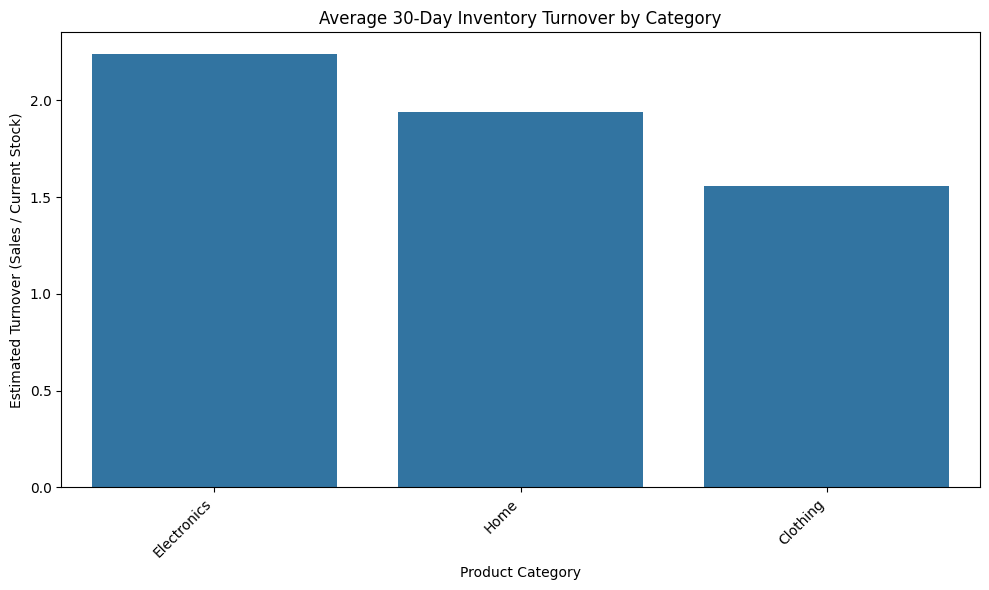

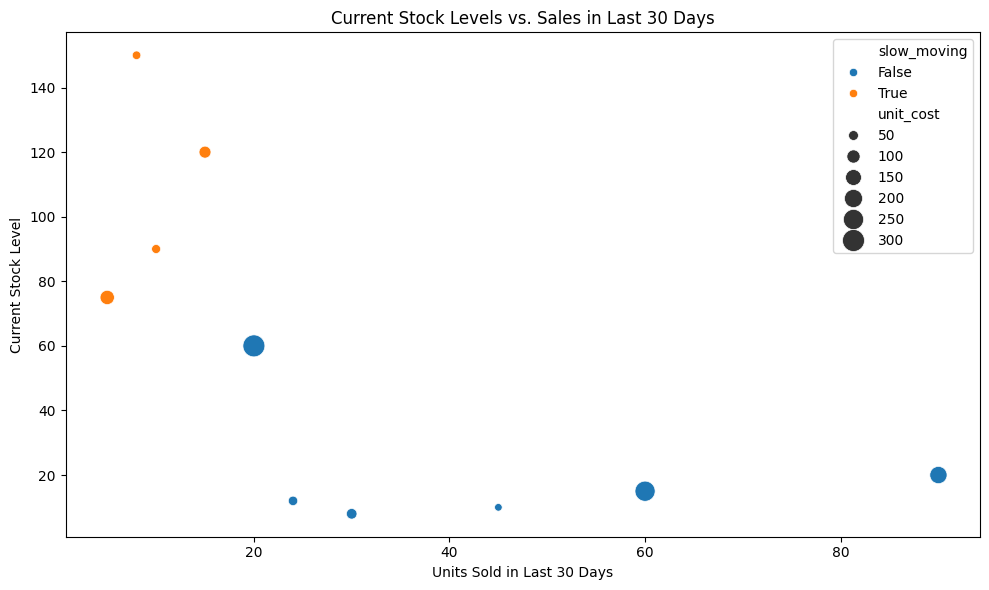

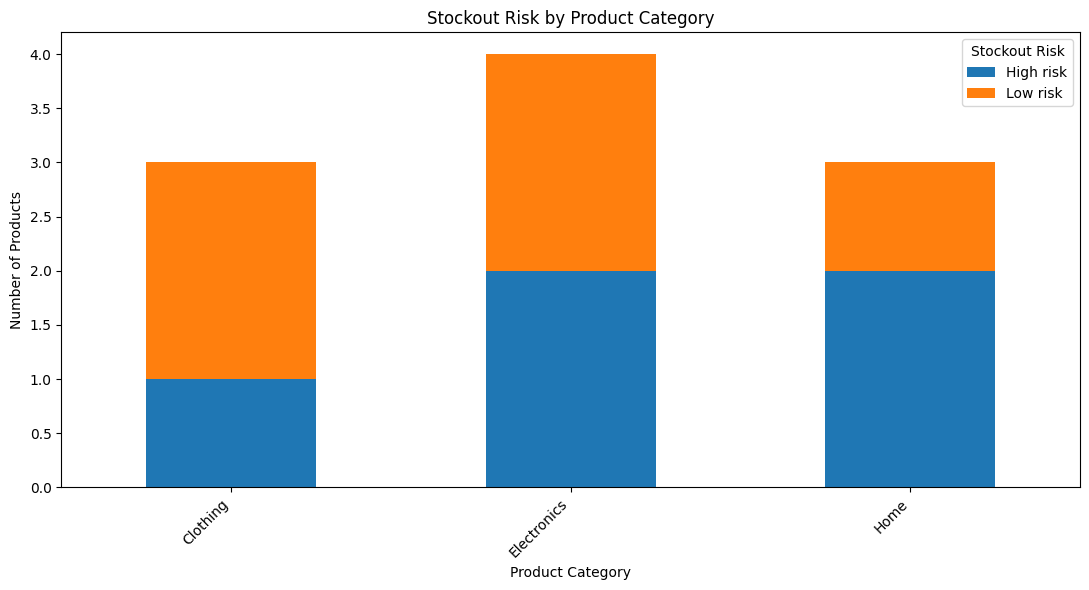

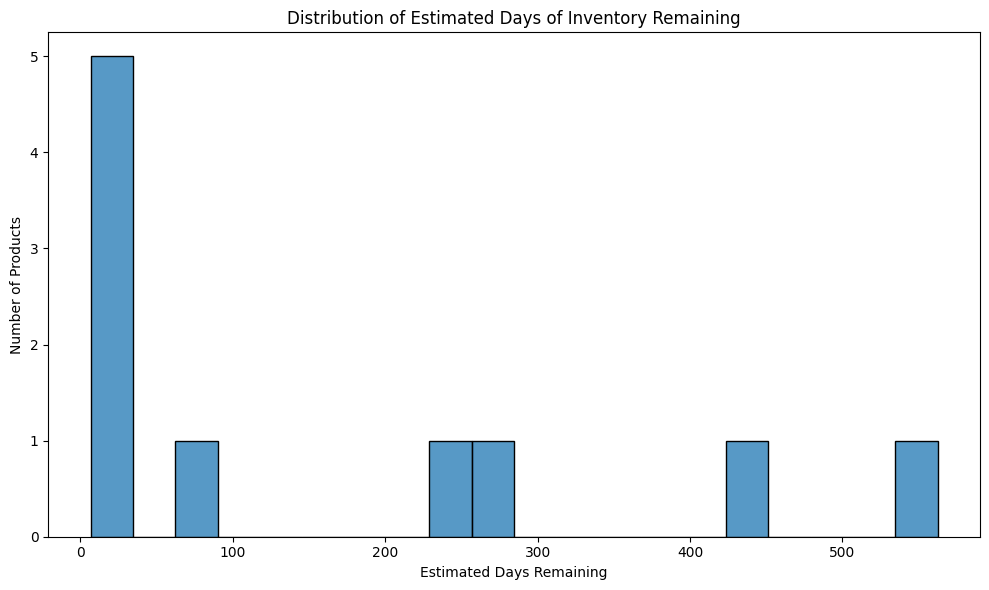


RETAIL INVENTORY ANALYSIS SUMMARY
Total products analyzed: 10
Slow-moving products: 4
High-risk products: 5
Products out of stock: 0
Medium-risk products: 0

TOP PRODUCTS TO PRIORITIZE FOR REPLENISHMENT
   product_id     category  stock_level  days_of_inventory  \
2         103     Clothing           10           6.666667   
6         107  Electronics           20           6.666667   
0         101  Electronics           15           7.500000   
4         105         Home            8           8.000000   
8         109         Home           12          15.000000   

   supplier_lead_time  reorder_quantity  
2                  10               5.0  
6                  14              22.0  
0                  14              13.0  
4                  12               4.0  
8                  15               0.0  

BUSINESS RECOMMENDATIONS
1. Prioritize out-of-stock and high-risk products.
2. Review slow-moving inventory for promotions or markdowns.
3. Compare turnover rates across 

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. PREPARE THE DATA
# ============================================================

# Assumes your inventory data is already loaded into df
df = df.copy()

df["last_restock_date"] = pd.to_datetime(
    df["last_restock_date"], errors="coerce"
)

numeric_cols = [
    "stock_level",
    "sales_last_30_days",
    "supplier_lead_time",
    "unit_cost"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing or invalid essential inventory values
df = df.dropna(
    subset=[
        "product_id",
        "category",
        "stock_level",
        "sales_last_30_days",
        "supplier_lead_time",
        "unit_cost"
    ]
).copy()

# Prevent negative values from distorting inventory calculations
df = df[
    (df["stock_level"] >= 0) &
    (df["sales_last_30_days"] >= 0) &
    (df["supplier_lead_time"] >= 0) &
    (df["unit_cost"] >= 0)
].copy()

print("DATA PREPARATION")
print("=" * 50)
print(f"Products analyzed: {len(df)}")
print(f"Missing values:\n{df.isnull().sum()}")


# ============================================================
# 2. CALCULATE INVENTORY TURNOVER
# ============================================================

# Average daily sales based on the last 30 days
df["daily_sales"] = df["sales_last_30_days"] / 30

# Estimated 30-day turnover proxy
# This is sales divided by current stock, not the formal
# accounting inventory turnover ratio.
df["inventory_turnover_30d"] = np.where(
    df["stock_level"] > 0,
    df["sales_last_30_days"] / df["stock_level"],
    np.nan
)

# Estimate days of inventory remaining
df["days_of_inventory"] = np.where(
    df["daily_sales"] > 0,
    df["stock_level"] / df["daily_sales"],
    np.inf
)

print("\nINVENTORY TURNOVER")
print("=" * 50)

print(
    df[[
        "product_id",
        "category",
        "stock_level",
        "sales_last_30_days",
        "inventory_turnover_30d",
        "days_of_inventory"
    ]].head(10)
)

# Traditional accounting turnover uses cost of goods sold
# divided by average inventory value. Those historical
# values are not available in this dataset.


# ============================================================
# 3. IDENTIFY SLOW-MOVING PRODUCTS
# ============================================================

# Flag products that sold 20% or less of current stock
df["slow_moving"] = (
    (df["stock_level"] > 0) &
    (
        df["sales_last_30_days"]
        <= 0.20 * df["stock_level"]
    )
)

slow_moving_items = df[
    df["slow_moving"]
].sort_values("inventory_turnover_30d")

print("\nSLOW-MOVING PRODUCTS")
print("=" * 50)

print(
    slow_moving_items[[
        "product_id",
        "category",
        "stock_level",
        "sales_last_30_days",
        "inventory_turnover_30d"
    ]]
)

print("\nSlow-moving products by category:")

print(
    slow_moving_items.groupby("category")["product_id"]
    .count()
    .sort_values(ascending=False)
)


# ============================================================
# 4. PREDICT POTENTIAL STOCKOUTS
# ============================================================

# A product is high risk when estimated inventory coverage
# is no greater than supplier lead time.
df["potential_stockout"] = (
    (df["daily_sales"] > 0) &
    (
        df["days_of_inventory"]
        <= df["supplier_lead_time"]
    )
)

# Baseline reorder quantity to cover demand during lead time.
# Safety stock and incoming shipments are not included.
df["reorder_quantity"] = np.maximum(
    0,
    np.ceil(
        df["daily_sales"] * df["supplier_lead_time"]
        - df["stock_level"]
    )
)

# Assign inventory risk categories
df["stockout_risk"] = np.select(
    [
        df["stock_level"] <= 0,
        df["potential_stockout"],
        (
            df["days_of_inventory"]
            <= df["supplier_lead_time"] + 7
        )
    ],
    [
        "Out of stock",
        "High risk",
        "Medium risk"
    ],
    default="Low risk"
)

print("\nSTOCKOUT PREDICTIONS")
print("=" * 50)

print(
    df.sort_values("days_of_inventory")[[
        "product_id",
        "category",
        "stock_level",
        "daily_sales",
        "days_of_inventory",
        "supplier_lead_time",
        "stockout_risk",
        "reorder_quantity"
    ]].head(20)
)


# ============================================================
# 5. VISUALIZATION 1: INVENTORY TURNOVER BY CATEGORY
# ============================================================

category_turnover = (
    df.groupby("category")["inventory_turnover_30d"]
    .mean()
    .reset_index()
    .sort_values("inventory_turnover_30d", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_turnover,
    x="category",
    y="inventory_turnover_30d"
)

plt.title("Average 30-Day Inventory Turnover by Category")
plt.xlabel("Product Category")
plt.ylabel("Estimated Turnover (Sales / Current Stock)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# 6. VISUALIZATION 2: STOCK LEVELS VS. SALES
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sales_last_30_days",
    y="stock_level",
    hue="slow_moving",
    size="unit_cost",
    sizes=(30, 250)
)

plt.title("Current Stock Levels vs. Sales in Last 30 Days")
plt.xlabel("Units Sold in Last 30 Days")
plt.ylabel("Current Stock Level")
plt.tight_layout()
plt.show()


# ============================================================
# 7. VISUALIZATION 3: STOCKOUT RISK BY CATEGORY
# ============================================================

risk_counts = (
    df.groupby(["category", "stockout_risk"])
    .size()
    .reset_index(name="product_count")
)

risk_pivot = risk_counts.pivot(
    index="category",
    columns="stockout_risk",
    values="product_count"
).fillna(0)

risk_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Stockout Risk by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Stockout Risk")
plt.tight_layout()
plt.show()


# ============================================================
# 8. VISUALIZATION 4: DAYS OF INVENTORY REMAINING
# ============================================================

# Infinite values occur when sales are zero.
# Exclude them from the histogram.
plot_df = df.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=["days_of_inventory"])

plt.figure(figsize=(10, 6))

sns.histplot(
    data=plot_df,
    x="days_of_inventory",
    bins=20
)

plt.title("Distribution of Estimated Days of Inventory Remaining")
plt.xlabel("Estimated Days Remaining")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


# ============================================================
# 9. BUSINESS SUMMARY
# ============================================================

print("\nRETAIL INVENTORY ANALYSIS SUMMARY")
print("=" * 50)

print(f"Total products analyzed: {len(df)}")
print(f"Slow-moving products: {df['slow_moving'].sum()}")
print(
    "High-risk products: "
    f"{(df['stockout_risk'] == 'High risk').sum()}"
)
print(
    "Products out of stock: "
    f"{(df['stockout_risk'] == 'Out of stock').sum()}"
)
print(
    "Medium-risk products: "
    f"{(df['stockout_risk'] == 'Medium risk').sum()}"
)

print("\nTOP PRODUCTS TO PRIORITIZE FOR REPLENISHMENT")
print("=" * 50)

priority_items = df[
    df["stockout_risk"].isin([
        "Out of stock",
        "High risk"
    ])
].sort_values("days_of_inventory")

print(
    priority_items[[
        "product_id",
        "category",
        "stock_level",
        "days_of_inventory",
        "supplier_lead_time",
        "reorder_quantity"
    ]].head(10)
)


# ============================================================
# 10. BUSINESS RECOMMENDATIONS
# ============================================================

print("\nBUSINESS RECOMMENDATIONS")
print("=" * 50)

print("1. Prioritize out-of-stock and high-risk products.")
print("2. Review slow-moving inventory for promotions or markdowns.")
print("3. Compare turnover rates across product categories.")
print("4. Consider supplier lead times when planning replenishment.")
print("5. Improve forecasts using historical sales and seasonality.")
print("6. Account for incoming shipments and safety stock before ordering.")

print("\nAnalysis complete.")


The results is usable however this method of reverse engineering a response has complications. Not only is it an additional step that creates back and fourth with the LLM - but it also leaves the direction of the project and thus the code into the LLM's hands for interpretation. This could potentially lead to unaligned buisness question responses and is not specifically steered towards a particular outcome. It also lacks fine tuned detail of what environments, libaries etc should be used.